In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
%matplotlib inline
import seaborn as sns

In [3]:
df = pd.read_csv("Diwali Sales Data.csv",encoding ='unicode_escape')

In [4]:
df.head(10)

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.00,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.00,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.00,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.00,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.00,NaN,NaN
5,1000588,Joni,P00057942,M,26-35,28,1,Himachal Pradesh,Northern,Food Processing,Auto,1,23877.00,NaN,NaN
6,1001132,Balk,P00018042,F,18-25,25,1,Uttar Pradesh,Central,Lawyer,Auto,4,23841.00,NaN,NaN
7,1002092,Shivangi,P00273442,F,55+,61,0,Maharashtra,Western,IT Sector,Auto,1,NaN,NaN,NaN
8,1003224,Kushal,P00205642,M,26-35,35,0,Uttar Pradesh,Central,Govt,Auto,2,23809.00,NaN,NaN
9,1003650,Ginny,P00031142,F,26-35,26,1,Andhra Pradesh,Southern,Media,Auto,4,23799.99,NaN,NaN


In [5]:
df.shape

(11251, 15)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  object 
 2   Product_ID        11251 non-null  object 
 3   Gender            11251 non-null  object 
 4   Age Group         11251 non-null  object 
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  object 
 8   Zone              11251 non-null  object 
 9   Occupation        11251 non-null  object 
 10  Product_Category  11251 non-null  object 
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), object(8)
memory usage: 1.3+ MB


In [7]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount', 'Status', 'unnamed1'],
      dtype='object')

In [8]:
df.drop(["Status","unnamed1"], axis=1 , inplace= True)

In [9]:
df.head(2)

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0


In [10]:
pd.isnull(df) .sum()

User_ID              0
Cust_name            0
Product_ID           0
Gender               0
Age Group            0
Age                  0
Marital_Status       0
State                0
Zone                 0
Occupation           0
Product_Category     0
Orders               0
Amount              12
dtype: int64

In [11]:
df.shape

(11251, 13)

In [12]:
df.dropna(inplace=True)

In [13]:
df.shape

(11239, 13)

In [14]:
df["Amount"] = df["Amount"].astype("int")

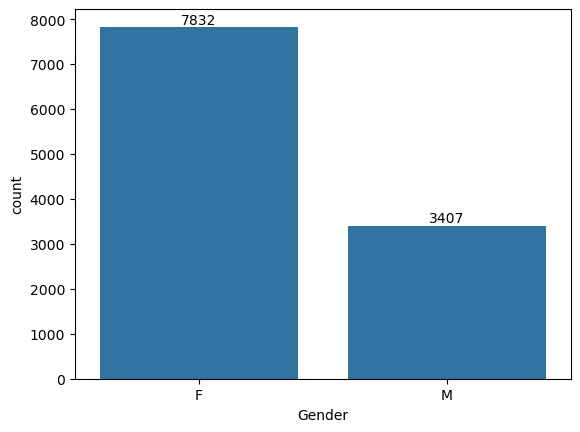

In [20]:
ar = sns.countplot(x = "Gender" , data = df)

for bars in ar.containers:
    ar.bar_label(bars)

In [21]:
df.groupby(["Gender"],as_index=False)["Amount"].sum().sort_values(by="Amount" , ascending=False)



,Gender,Amount
0,F,74335853
1,M,31913276


<Axes: xlabel='Gender', ylabel='Amount'>

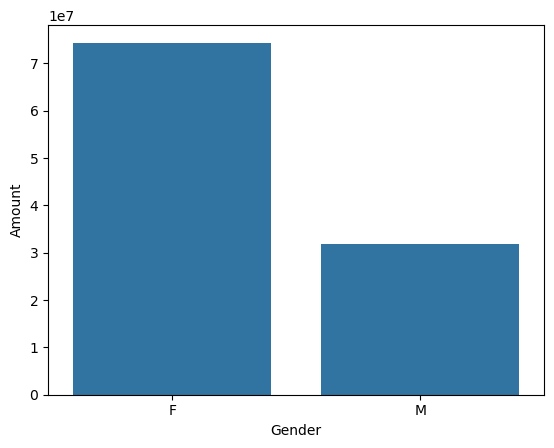

In [22]:
sales_gen = df.groupby(["Gender"],as_index=False)["Amount"].sum().sort_values(by="Amount" , ascending=False)

sns.barplot(x = "Gender" , y = "Amount" , data = sales_gen)

In [23]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

In [24]:
df.head(1)

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952


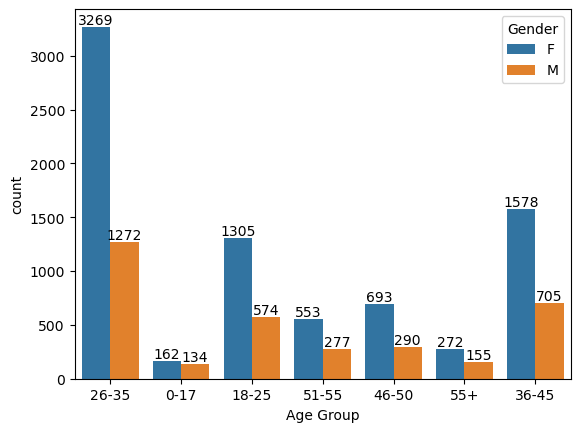

In [25]:
# Age group count by gender 
ax = sns.countplot(data = df , x = "Age Group" , hue = "Gender")

for bars in ax.containers:
    ax.bar_label(bars)

<Axes: xlabel='Age Group', ylabel='Amount'>

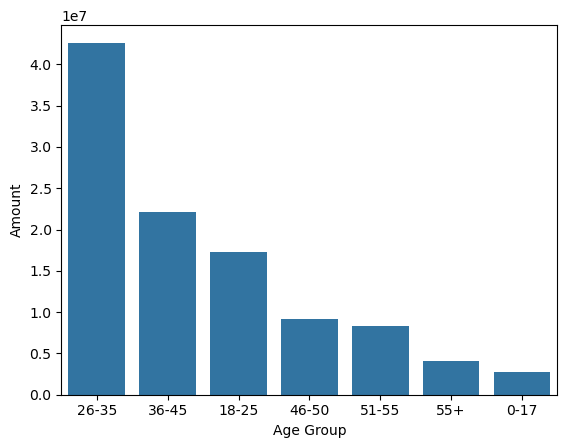

In [27]:
# Total Amount vs Age Group
sales_age = df.groupby(["Age Group"], as_index=False)["Amount"].sum().sort_values(by = "Amount" , ascending=False)
sns.barplot(x  ="Age Group" , y = "Amount" , data = sales_age)

<Axes: xlabel='State', ylabel='Orders'>

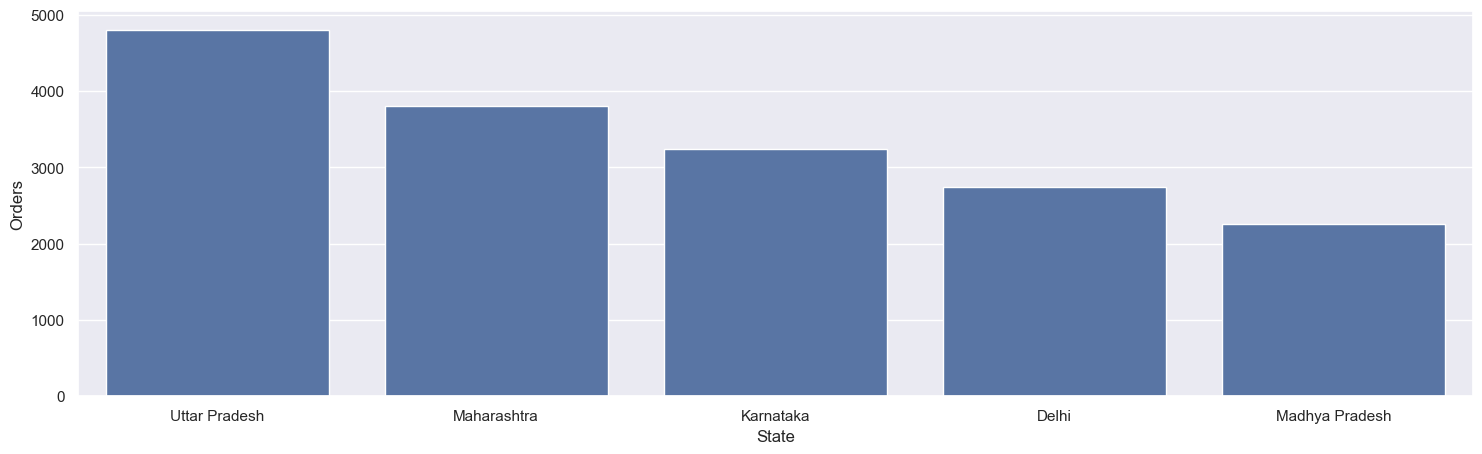

In [32]:
# Top 5 state by orders 

sales_state = df.groupby(["State"],as_index=False)["Orders"].sum().sort_values(by="Orders" , ascending=False).head(5)
sns.set(rc={"figure.figsize" : (18,5)})
sns.barplot(data = sales_state , x="State" , y = "Orders")


<Axes: xlabel='State', ylabel='Amount'>

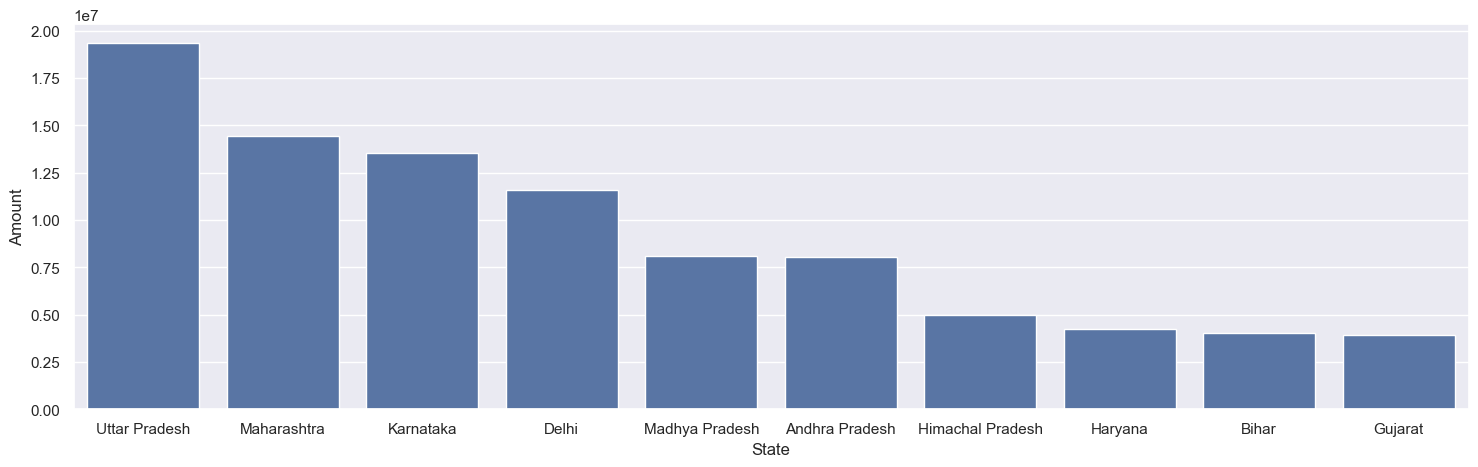

In [35]:
# top 10 total_sales by state

sales_state = df.groupby(["State"],as_index=False)["Amount"].sum().sort_values(by="Amount" , ascending=False).head(10)
sns.set(rc={"figure.figsize" : (18,5)})
sns.barplot(data = sales_state , x="State" , y = "Amount")


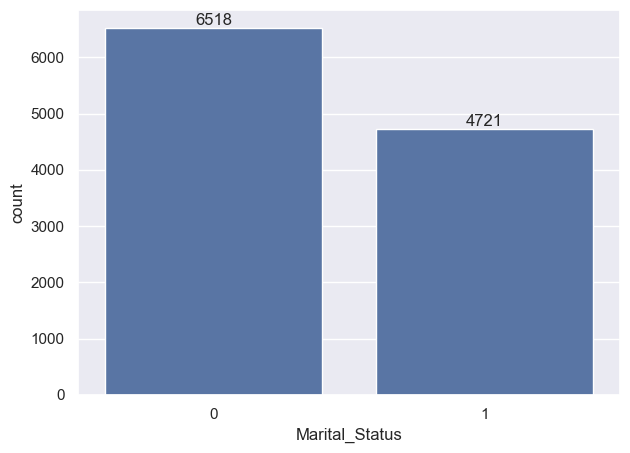

In [39]:
# Marital_Status 

ar1 = sns.countplot(data = df , x = "Marital_Status")
sns.set(rc={"figure.figsize" : (7,5)})
for bars in ar1.containers:
    ar1.bar_label(bars)

<Axes: xlabel='Marital_Status', ylabel='Amount'>

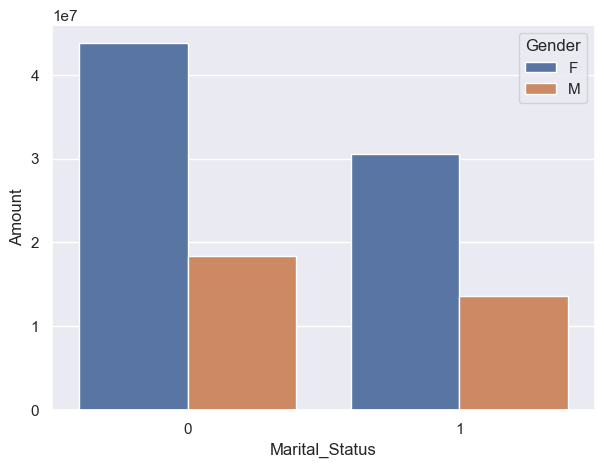

In [40]:
sales_state  = df.groupby(["Marital_Status" , "Gender"],as_index=False)["Amount"].sum().sort_values(by="Amount" , ascending=False)

sns.barplot(data = sales_state , x = "Marital_Status" , y = "Amount" , hue = "Gender")

In [ ]:
# Occupation

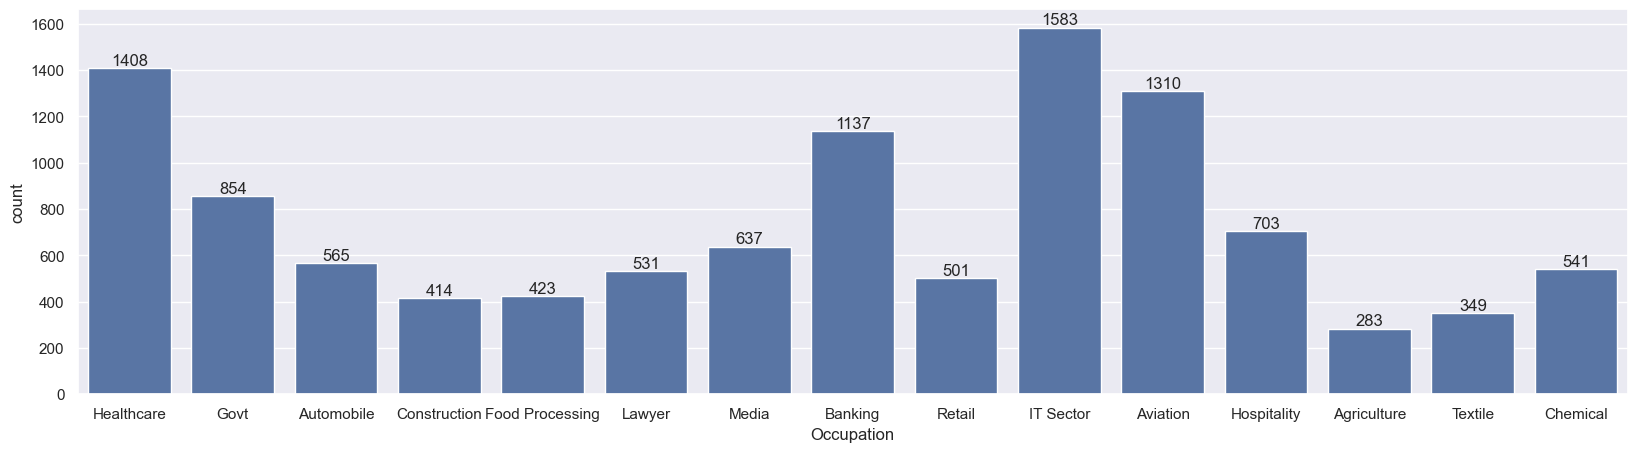

In [43]:
sns.set(rc={"figure.figsize" : (20,5)})
ar = sns.countplot(x ="Occupation", data =df)

for bars in ar.containers:
    ar.bar_label(bars)


<Axes: xlabel='Occupation', ylabel='Amount'>

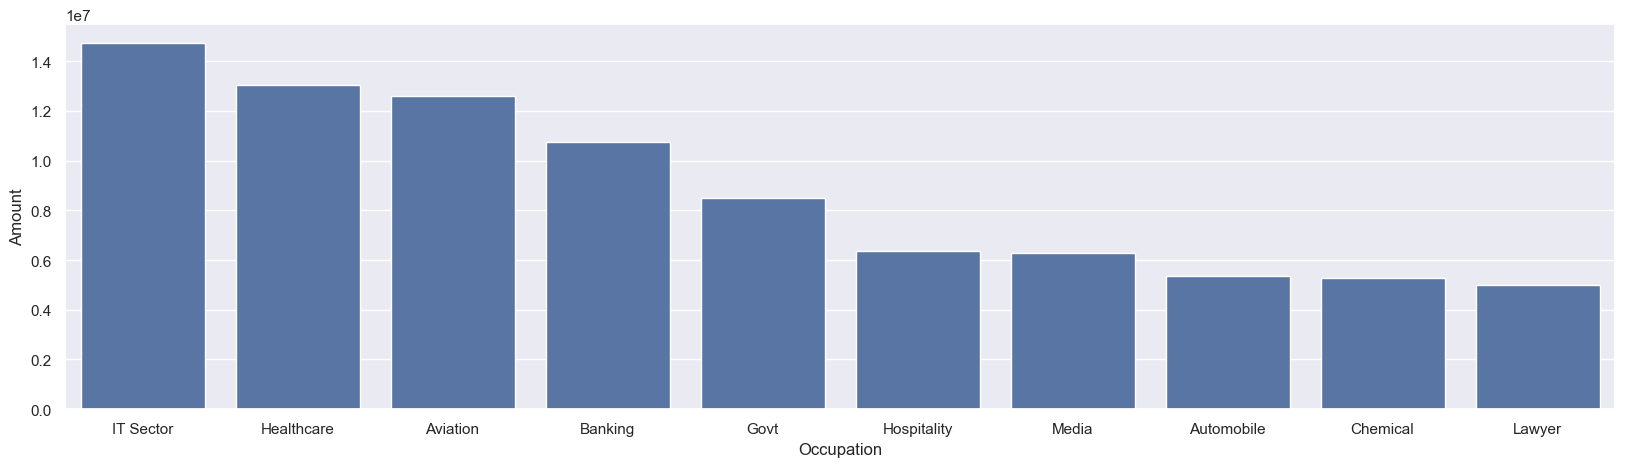

In [46]:
# top 10 sales by occupation 

sales_state = df.groupby(["Occupation"],as_index=False)["Amount"].sum().sort_values(by = "Amount" , ascending=False).head(10)
sns.set(rc={"figure.figsize" : (20,5)})
sns.barplot(x="Occupation" ,y ="Amount" , data = sales_state)


In [49]:
df.columns


Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

In [ ]:
# PRODUCT 

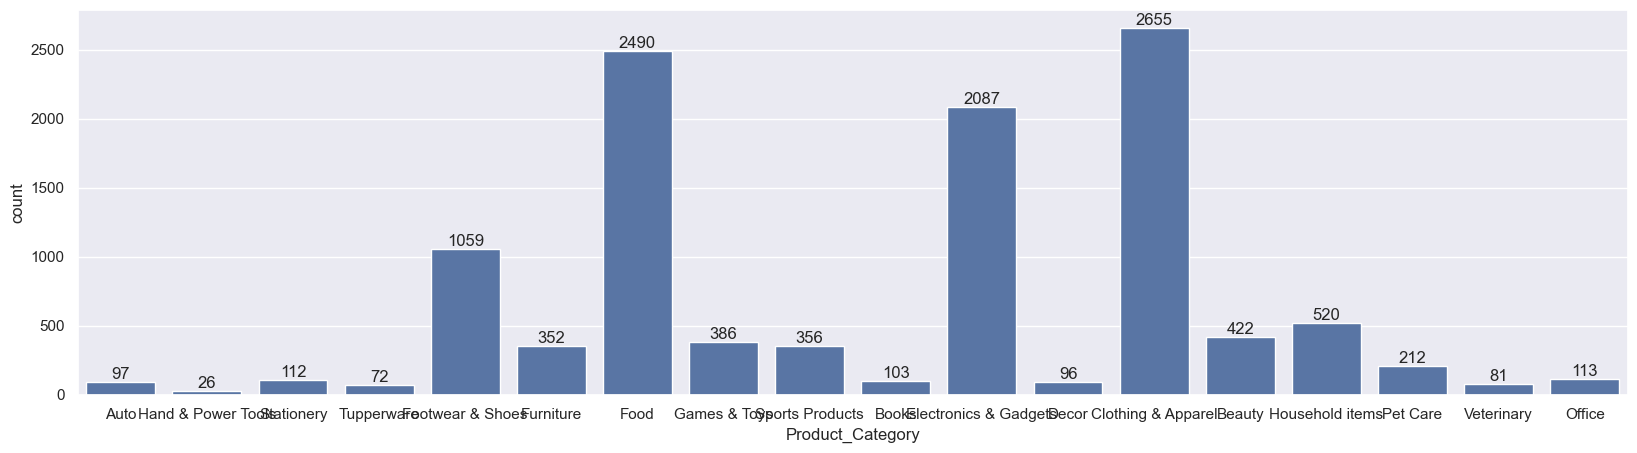

In [55]:
sns.set(rc={"figure.figsize" : (20,5)})
ar = sns.countplot(x ="Product_Category", data =df)

for bars in ar.containers:
    ar.bar_label(bars)


<Axes: xlabel='Product_Category', ylabel='Amount'>

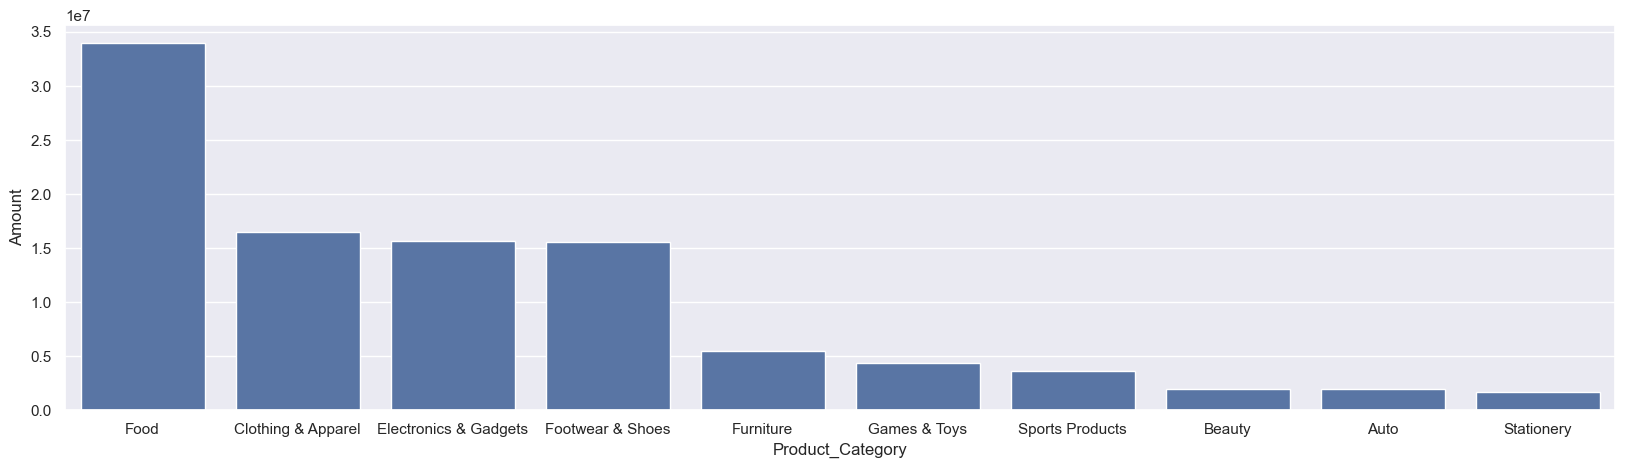

In [53]:

product_sales = df.groupby(["Product_Category"],as_index=False)["Amount"].sum().sort_values(by = "Amount" , ascending=False).head(10)
sns.set(rc={"figure.figsize" : (20,5)})
sns.barplot(x="Product_Category" ,y ="Amount" , data = product_sales)


<Axes: xlabel='Product_ID', ylabel='Orders'>

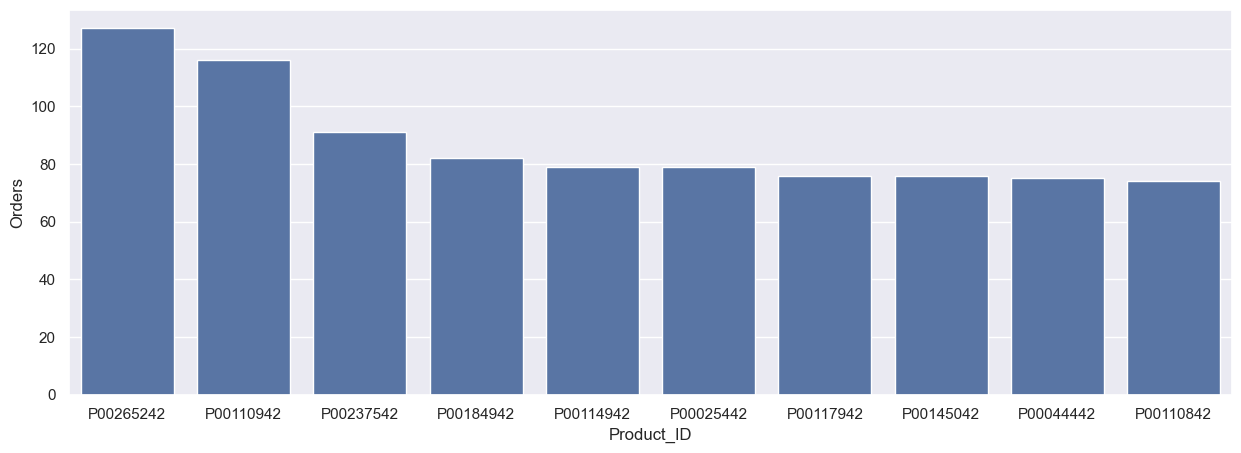

In [19]:

product_sales = df.groupby(["Product_ID"],as_index=False)["Orders"].sum().sort_values(by = "Orders" , ascending=False).head(10)
sns.set(rc={"figure.figsize" : (15,5)})
sns.barplot(x="Product_ID" ,y ="Orders" , data = product_sales)
